# Six-Chip Model SSIM Results

Comparison of five **fine-tuned backbone models** and three **full-training models**. All values below use **per-chip-range SSIM**. Weighted SSIM weights chips by their number of test samples; macro SSIM gives every chip equal weight.

The values were transcribed from the saved evaluation outputs in the corresponding model notebooks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 17, 'axes.labelsize': 14})

chips = ['Vortex-small', 'nvdla-small', 'openc910-1', 'RISCY', 'RISCY-FPU', 'zero-riscy']
fine_tuned_models = ['ResNet50V2', 'DenseNet121', 'MobileNetV2', 'NASNetMobile', 'Xception']
full_training_models = ['U-Net', 'ViT', 'FPN']
model_order = fine_tuned_models + full_training_models

results = {
    'ResNet50V2':  [0.835009, 0.887550, 0.958204, 0.890683, 0.928250, 0.879217, 0.899425, 0.896486],
    'DenseNet121':  [0.809138, 0.870413, 0.943937, 0.875693, 0.914100, 0.864159, 0.884577, 0.879573],
    'MobileNetV2':  [0.838574, 0.883093, 0.949389, 0.855241, 0.896501, 0.849819, 0.868082, 0.878769],
    'NASNetMobile': [0.838574, 0.883093, 0.949389, 0.855241, 0.896501, 0.849819, 0.868082, 0.878769],
    'Xception':     [0.823577, 0.887897, 0.948762, 0.861991, 0.903249, 0.855070, 0.874042, 0.880091],
    'U-Net':        [0.789631, 0.866300, 0.910609, 0.899813, 0.925650, 0.893927, 0.905248, 0.880988],
    'ViT':          [0.817321, 0.889368, 0.912280, 0.875457, 0.908774, 0.866360, 0.883412, 0.878260],
    'FPN':          [0.866381, 0.906040, 0.937955, 0.919325, 0.946582, 0.909540, 0.924709, 0.914304],
}

columns = chips + ['Weighted SSIM', 'Macro SSIM']
results_df = pd.DataFrame.from_dict(results, orient='index', columns=columns).loc[model_order]
results_df.index.name = 'Model'

In [2]:
fine_color = '#2A9D8F'
full_color = '#E76F51'
model_colors = dict(zip(model_order, plt.cm.tab10.colors[:len(model_order)]))

def add_value_labels(ax, bars, decimals=3, fontsize=10):
    for bar in bars:
        value = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.002, f'{value:.{decimals}f}',
                ha='center', va='bottom', fontsize=fontsize, rotation=90)

def aggregate_plot(metric, title):
    values = results_df[metric].to_numpy()
    x = np.r_[np.arange(5), np.arange(3) + 6]
    colors = [fine_color] * 5 + [full_color] * 3
    fig, ax = plt.subplots(figsize=(14, 7))
    bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.7)
    add_value_labels(ax, bars)
    ax.set_xticks(x, model_order, rotation=30, ha='right')
    ax.set_ylabel('SSIM score')
    ax.set_title(title, weight='bold', pad=18)
    ax.set_ylim(0.5, 1.0)
    ax.axvline(5.5, color='0.35', linestyle='--', linewidth=1.2)
    ax.text(2, ax.get_ylim()[1] - 0.006, 'Fine Tuning', ha='center', va='top', weight='bold', color=fine_color)
    ax.text(7, ax.get_ylim()[1] - 0.006, 'Full Training', ha='center', va='top', weight='bold', color=full_color)
    #ax.legend(handles=[Patch(facecolor=fine_color, label='Fine Tuning'), Patch(facecolor=full_color, label='Full Training')], loc='lower right')
    ax.grid(axis='x', visible=False)
    fig.tight_layout()
    plt.show()

## Overall weighted SSIM

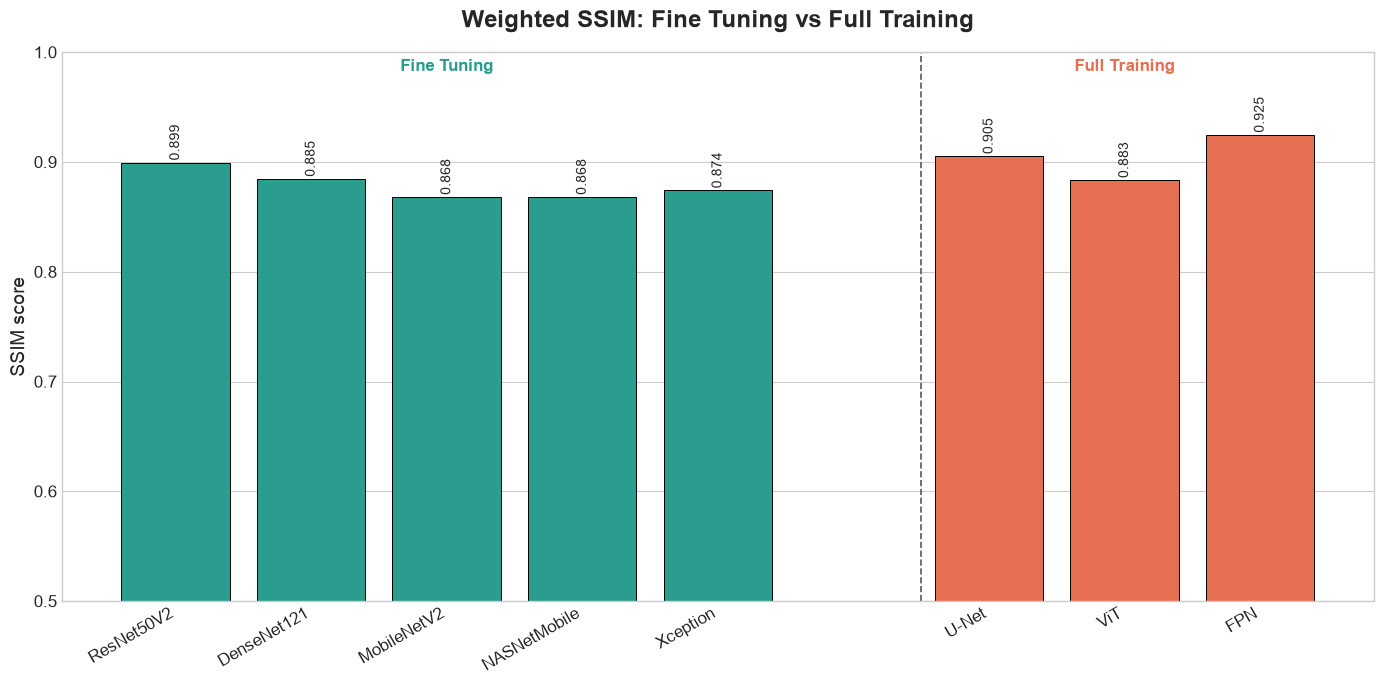

In [3]:
aggregate_plot('Weighted SSIM', 'Weighted SSIM: Fine Tuning vs Full Training')

## Overall unweighted (macro) SSIM

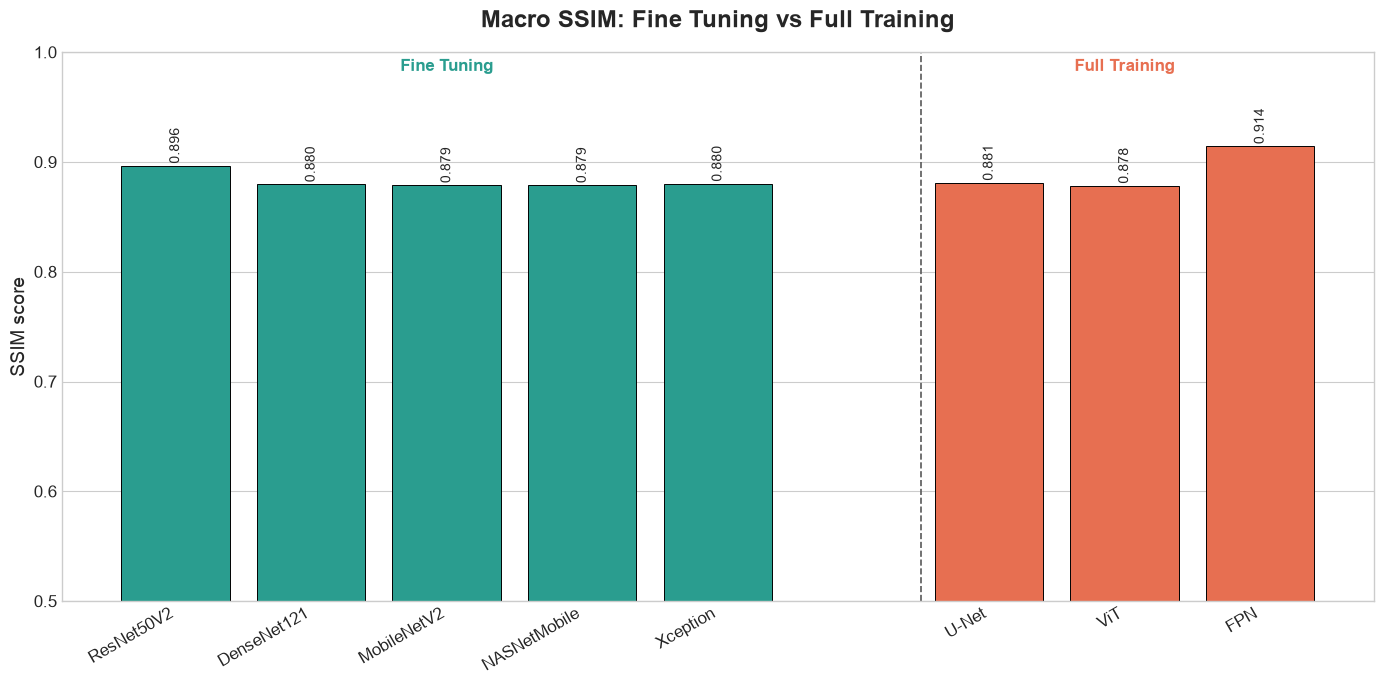

In [4]:
aggregate_plot('Macro SSIM', 'Macro SSIM: Fine Tuning vs Full Training')

## Per-chip SSIM for the five fine-tuned models

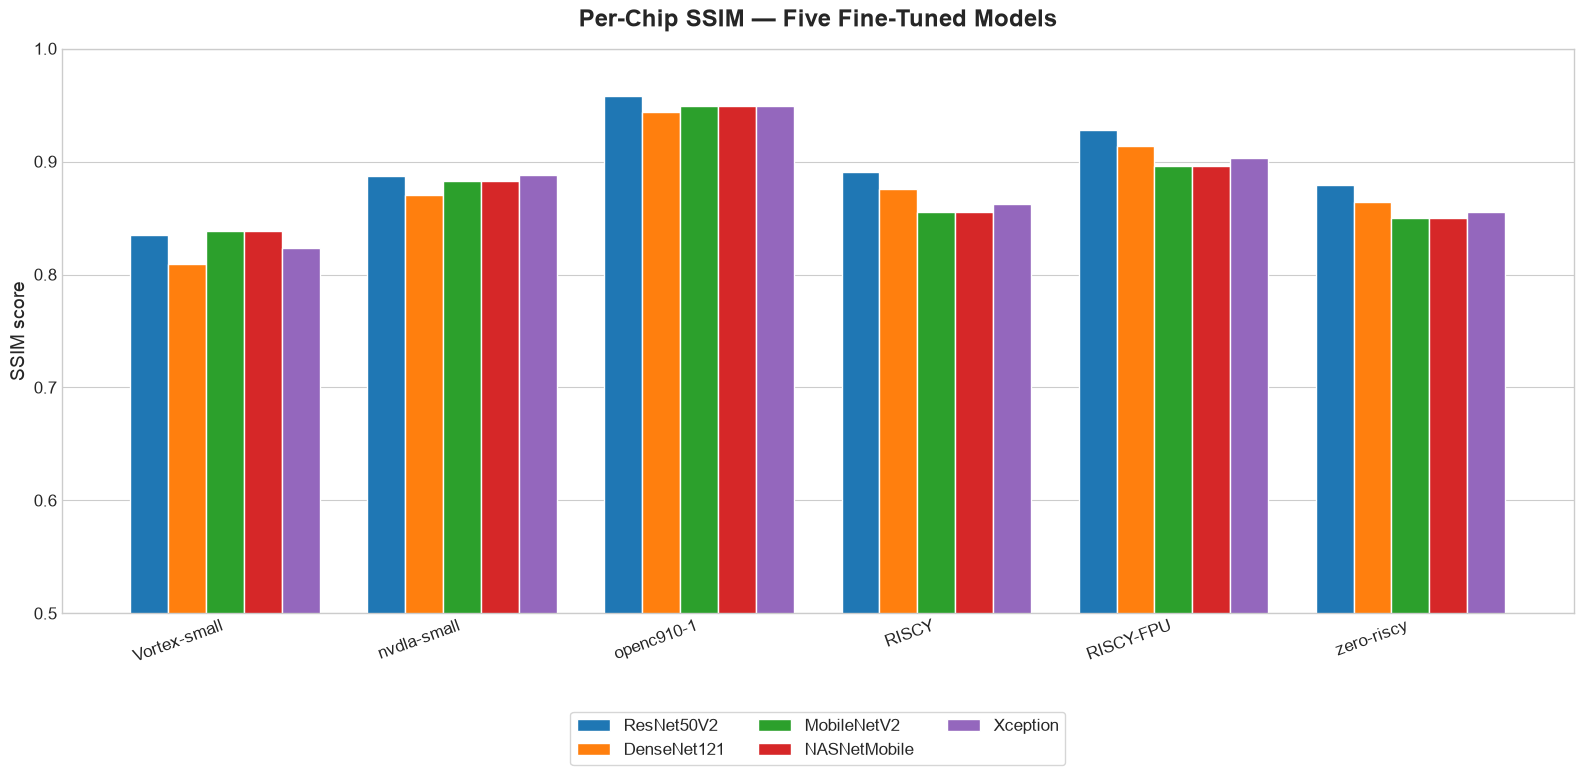

In [5]:
x = np.arange(len(chips))
width = 0.16
fig, ax = plt.subplots(figsize=(16, 8))
for i, model in enumerate(fine_tuned_models):
    ax.bar(x + (i - 2) * width, results_df.loc[model, chips], width, label=model, color=model_colors[model], edgecolor='white')
ax.set_xticks(x, chips, rotation=20, ha='right')
ax.set_ylabel('SSIM score')
ax.set_title('Per-Chip SSIM — Five Fine-Tuned Models', weight='bold', pad=16)
ax.set_ylim(0.5, 1.0)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.16), frameon=True)
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## Per-chip SSIM for the three full-training models

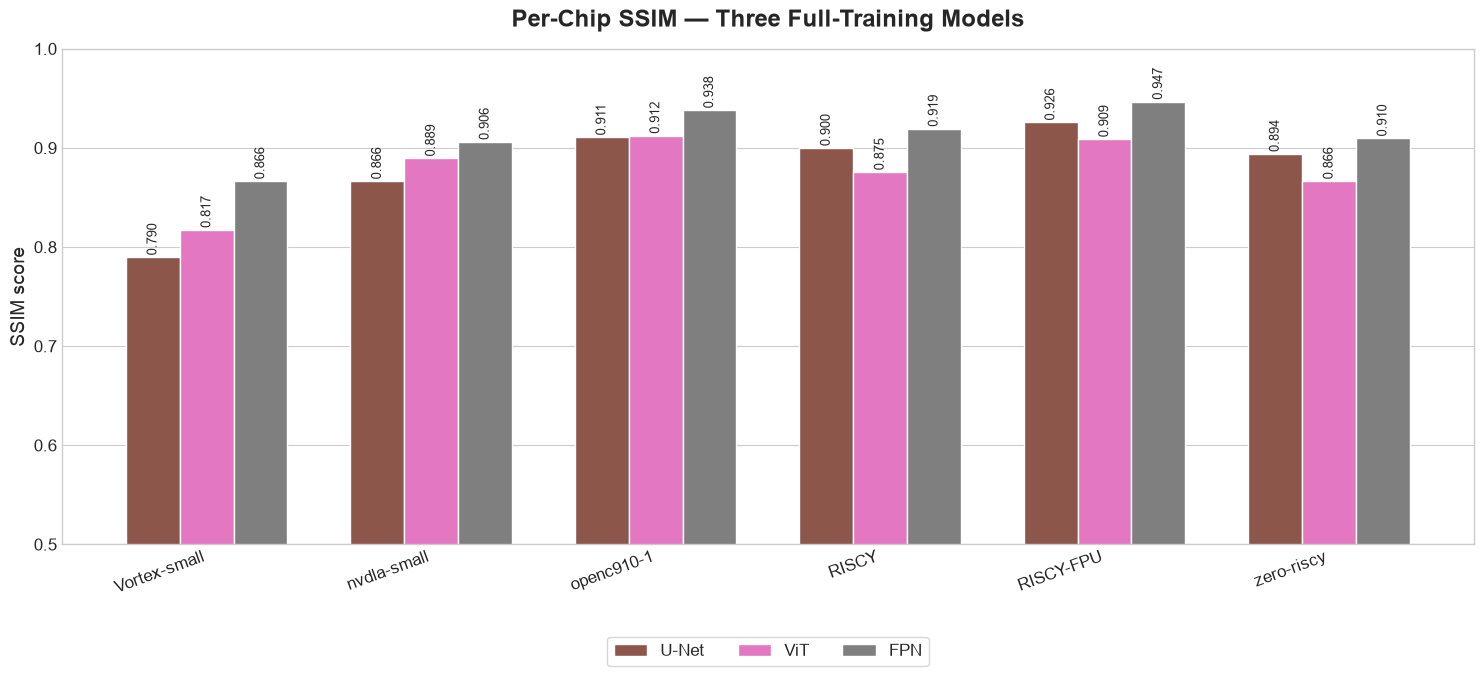

In [6]:
x = np.arange(len(chips))
width = 0.24
fig, ax = plt.subplots(figsize=(15, 7))
for i, model in enumerate(full_training_models):
    bars = ax.bar(x + (i - 1) * width, results_df.loc[model, chips], width, label=model, color=model_colors[model], edgecolor='white')
    add_value_labels(ax, bars, decimals=3, fontsize=9)
ax.set_xticks(x, chips, rotation=20, ha='right')
ax.set_ylabel('SSIM score')
ax.set_title('Per-Chip SSIM — Three Full-Training Models', weight='bold', pad=16)
ax.set_ylim(0.5, 1.0)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.17), frameon=True)
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## FPN input ablation study

Test SSIM for single-input (`only_*`) and leave-one-input-out (`drop_*`) FPN ablations.

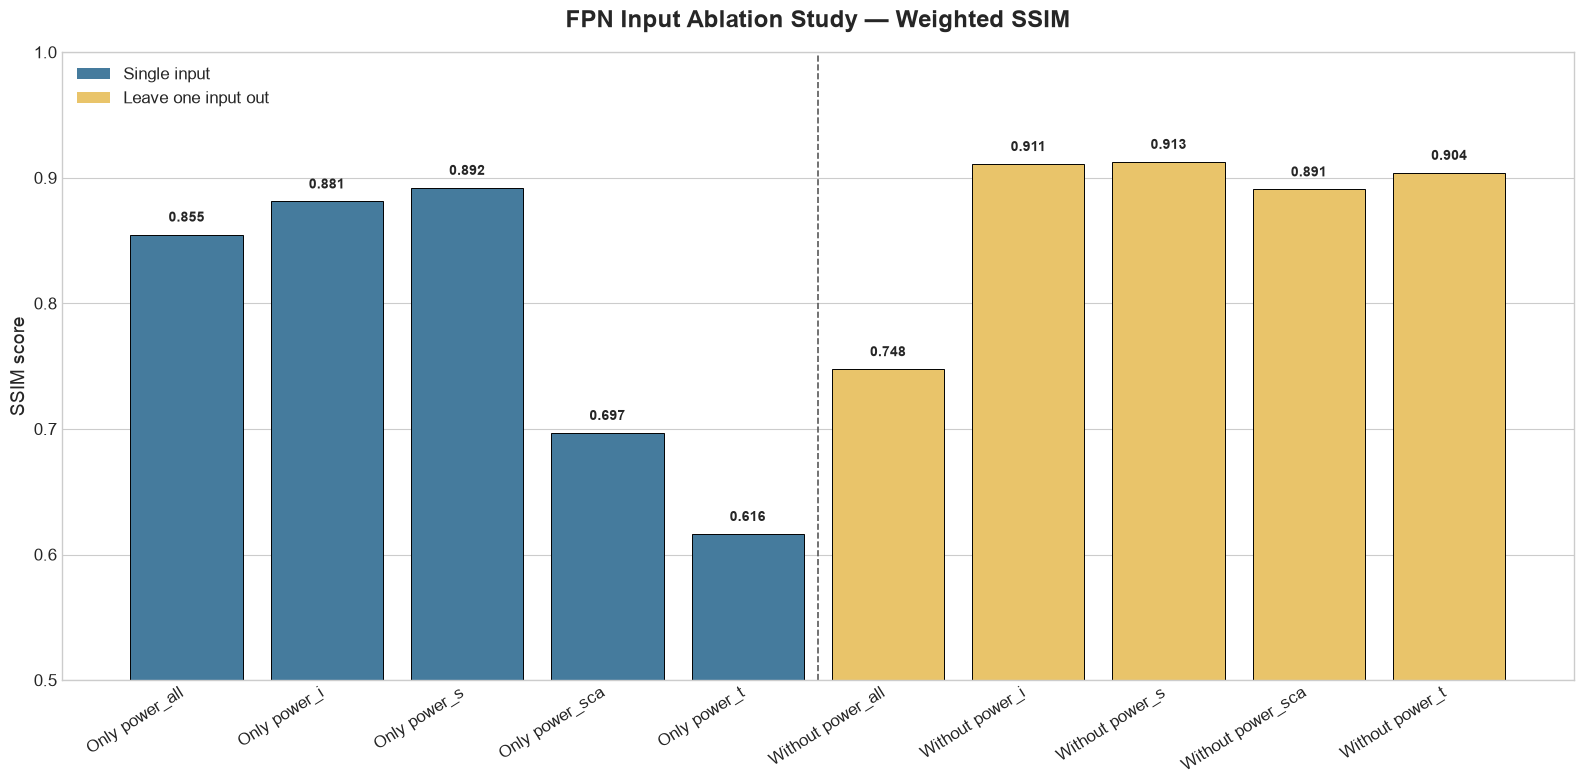

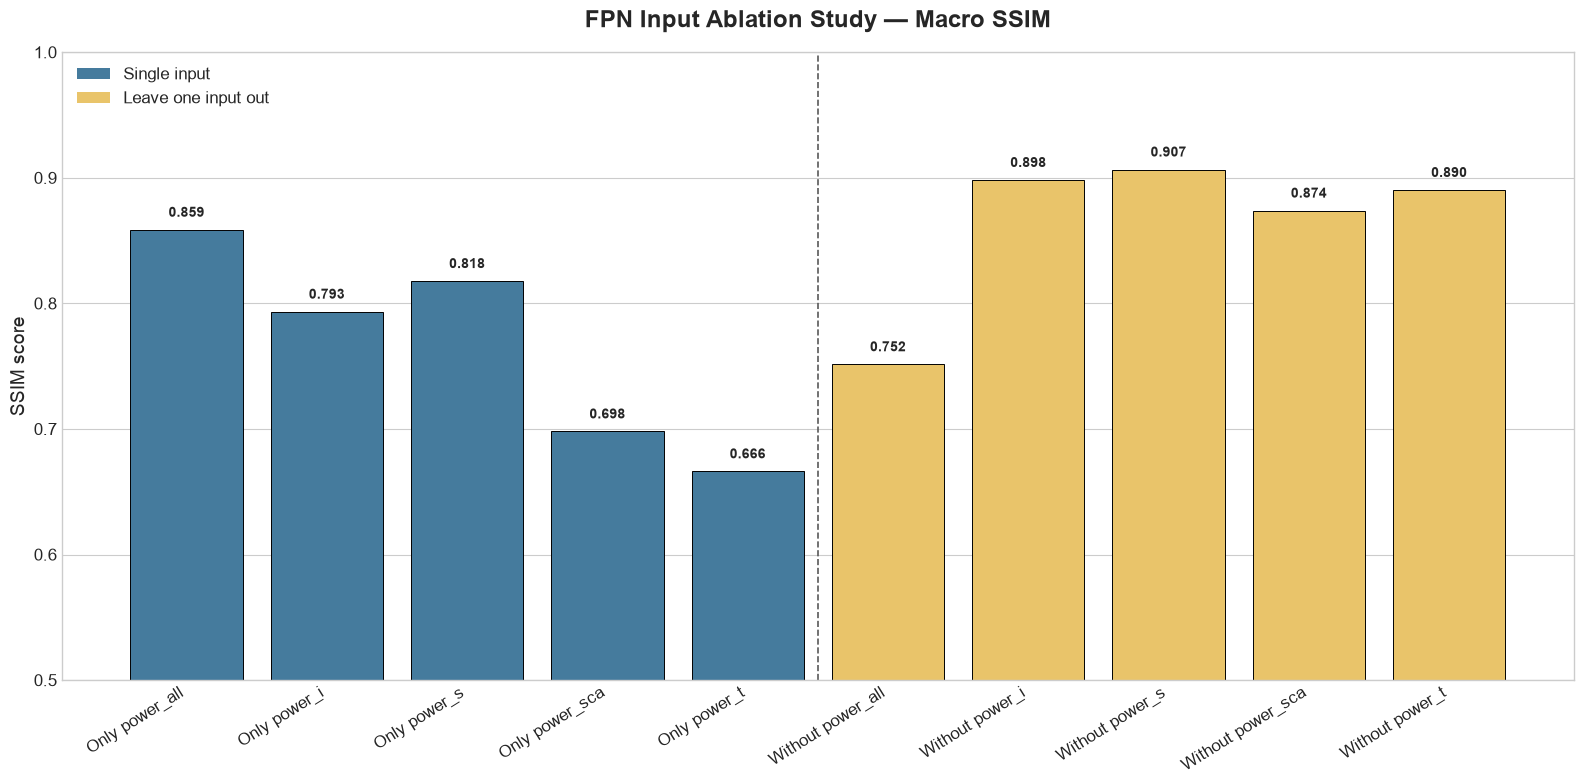

In [7]:
ablation_df = pd.DataFrame({
    'run_id': ['only_pall', 'only_pi', 'only_ps', 'only_psca', 'only_pt', 'drop_pall', 'drop_pi', 'drop_ps', 'drop_psca', 'drop_pt'],
    'Weighted SSIM': [0.854787, 0.881142, 0.891987, 0.696798, 0.616355, 0.747616, 0.910948, 0.912674, 0.890767, 0.903927],
    'Macro SSIM': [0.858623, 0.793404, 0.817766, 0.698033, 0.666253, 0.751506, 0.898254, 0.906585, 0.873874, 0.890290],
})
ablation_labels = {
    'only_pall': 'Only power_all', 'only_pi': 'Only power_i',
    'only_ps': 'Only power_s', 'only_psca': 'Only power_sca',
    'only_pt': 'Only power_t', 'drop_pall': 'Without power_all',
    'drop_pi': 'Without power_i', 'drop_ps': 'Without power_s',
    'drop_psca': 'Without power_sca', 'drop_pt': 'Without power_t',
}
ablation_df['label'] = ablation_df['run_id'].map(ablation_labels)
ablation_colors = np.where(ablation_df['run_id'].str.startswith('only_'), '#457B9D', '#E9C46A')

def ablation_plot(metric, title):
    fig, ax = plt.subplots(figsize=(16, 8))
    bars = ax.bar(ablation_df['label'], ablation_df[metric], color=ablation_colors, edgecolor='black', linewidth=0.7)
    for bar, value in zip(bars, ablation_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.008, f'{value:.3f}', ha='center', va='bottom', fontsize=10, weight='bold')
    ax.axvline(4.5, color='0.35', linestyle='--', linewidth=1.2)
    ax.set_xticks(range(len(ablation_df)), ablation_df['label'], rotation=32, ha='right')
    ax.set_ylabel('SSIM score')
    ax.set_title(title, weight='bold', pad=18)
    ax.set_ylim(0.5, 1.0)
    ax.legend(handles=[Patch(facecolor='#457B9D', label='Single input'), Patch(facecolor='#E9C46A', label='Leave one input out')], loc='upper left')
    ax.grid(axis='x', visible=False)
    fig.tight_layout()
    plt.show()

ablation_plot('Weighted SSIM', 'FPN Input Ablation Study — Weighted SSIM')
ablation_plot('Macro SSIM', 'FPN Input Ablation Study — Macro SSIM')

## Complete eight-model SSIM table

In [7]:
# Recorded total training runtimes from the saved notebook outputs
training_time_hours = {
    'ResNet50V2': 6.65,
    'DenseNet121': 8.52,
    'MobileNetV2': 3.50,
    'NASNetMobile': 6.12,
    'Xception': 8.06,
    'U-Net': 5.77,
    'ViT': 3.56,
    'FPN': 6.95,
}

# Create the final table without changing the original results dataframe
table_df = results_df.copy()
table_df['Time Trained (hours)'] = pd.Series(training_time_hours)

ssim_columns = chips + ['Weighted SSIM', 'Macro SSIM']

display(
    table_df.style
        .format({
            **{column: '{:.6f}' for column in ssim_columns},
            'Time Trained (hours)': '{:.2f}',
        })
        .set_caption(
            'Per-chip-range SSIM results and training time for all eight models'
        )
        .background_gradient(
            cmap='YlGn',
            axis=0,
            subset=ssim_columns
        )
        .set_properties(
            **{
                'text-align': 'center',
                'font-size': '11pt',
            }
        )
        .set_table_styles([
            {
                'selector': 'caption',
                'props': [
                    ('font-size', '16pt'),
                    ('font-weight', 'bold'),
                    ('margin-bottom', '10px'),
                ],
            },
            {
                'selector': 'th',
                'props': [
                    ('text-align', 'center'),
                    ('font-size', '11pt'),
                ],
            },
        ])
)

,Vortex-small,nvdla-small,openc910-1,RISCY,RISCY-FPU,zero-riscy,Weighted SSIM,Macro SSIM,Time Trained (hours)
Model,,,,,,,,,
ResNet50V2,0.835009,0.887550,0.958204,0.890683,0.928250,0.879217,0.899425,0.896486,6.65
DenseNet121,0.809138,0.870413,0.943937,0.875693,0.914100,0.864159,0.884577,0.879573,8.52
MobileNetV2,0.838574,0.883093,0.949389,0.855241,0.896501,0.849819,0.868082,0.878769,3.50
NASNetMobile,0.838574,0.883093,0.949389,0.855241,0.896501,0.849819,0.868082,0.878769,6.12
Xception,0.823577,0.887897,0.948762,0.861991,0.903249,0.855070,0.874042,0.880091,8.06
U-Net,0.789631,0.866300,0.910609,0.899813,0.925650,0.893927,0.905248,0.880988,5.77
ViT,0.817321,0.889368,0.912280,0.875457,0.908774,0.866360,0.883412,0.878260,3.56
FPN,0.866381,0.906040,0.937955,0.919325,0.946582,0.909540,0.924709,0.914304,6.95
